In [8]:
# Early Stopping
# from tensorflow.keras.callbacks import EarlyStopping
# callback = EarlyStopping(
#     monitor="val_loss",
#     min_delta=0.00001,
#     patience=20,
#     verbose=1,
#     mode="auto",
#     baseline=None,
#     restore_best_weights=False
# )
# history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=3500, callbacks=callback)

In [10]:
# Dropout 

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [13]:
X_train = np. linspace(-1, 1, 20)
y_train = np.array([-0.6561, -0.3099, -0.59035, -0.50855, -0.285,
                    0.2443,-0.02445, 0.00135, -0.2006, 0.07475,
                    0.1422, 0.06515, 0.15265,0.3521,0.28415,
                    0.5524 , 0.23115,
                    0.20835, 0.4211, 0.60485])
X_test = np. linspace(-1, 1, 20)

y_test = np.array ([-0.69415, -0.451, -0.43005, -0.4484, -0.1475,-0.5019,
                    -0.28055,0.24595, -0.21425, -0.0286,0.23415,0.46575, 0.07955,
                    0.1973, 0.0719, 0.3639, 0.5536 ,
                    0.3365 , 0.50705, 0.33435])

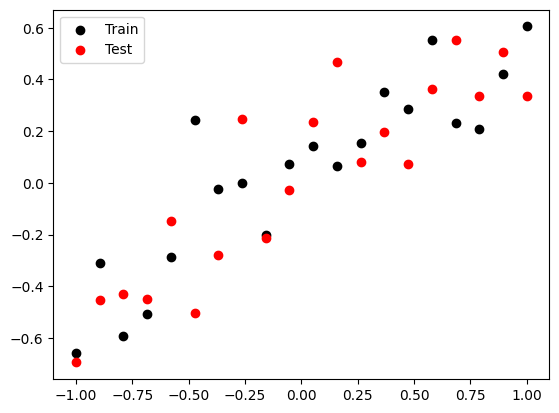

In [14]:
plt. scatter(X_train, y_train, c='black', label='Train')
plt.scatter(X_test, y_test, c='red', label='Test')
plt.legend()
plt.show()

In [15]:
model = Sequential()

model.add(Dense(128, input_dim=1, activation="relu"))
model.add(Dense(128,activation='relu'))
model.add(Dense(1,activation="linear"))

adam =Adam(learning_rate=0.01)
model.compile(loss='mse',optimizer=adam, metrics=['mse'])

history= model.fit(X_train,y_train,epochs=500, validation_data = (X_test,y_test),verbose=False)

C:\Users\PMLS\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [16]:
_, train_mse = model.evaluate(X_train,y_train,verbose=0)
_, test_mse = model.evaluate(X_test,y_test,verbose=0)
print('Train: {}, Test: {}'.format(train_mse,test_mse))

Train: 0.002639076206833124, Test: 0.06155801936984062


In [17]:
y_pred = model.predict(X_test)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step


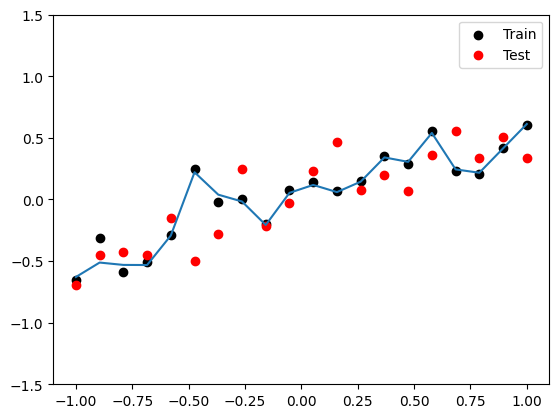

In [18]:

from prompt_toolkit.shortcuts.progress_bar import Label
plt.figure()
plt.scatter(X_train,y_train, c='black',label='Train')
plt.scatter(X_test,y_test,c='red',label='Test')
plt.plot(X_test,y_pred)
plt.legend()
plt.ylim((-1.5,1.5))
plt.show()
     

In [19]:
model = Sequential()

model.add(Dense(128, input_dim=1, activation="relu"))
model.add(Dropout(0.2))
model.add(Dense(128,activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(1,activation="linear"))

adam =Adam(learning_rate=0.01)
model.compile(loss='mse',optimizer=adam, metrics=['mse'])

history= model.fit(X_train,y_train,epochs=500, validation_data = (X_test,y_test),verbose=False)
     

In [20]:

_, train_mse = model.evaluate(X_train,y_train,verbose=0)
_, test_mse = model.evaluate(X_test,y_test,verbose=0)
print('Train: {}, Test: {}'.format(train_mse,test_mse))

Train: 0.013009483925998211, Test: 0.04697108268737793


In [21]:
y_pred = model.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step


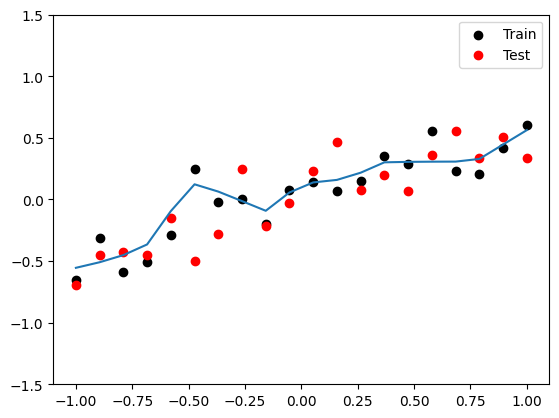

In [22]:
plt.figure()
plt.scatter(X_train,y_train, c='black',label='Train')
plt.scatter(X_test,y_test,c='red',label='Test')
plt.plot(X_test,y_pred)
plt.legend()
plt.ylim((-1.5,1.5))
plt.show()

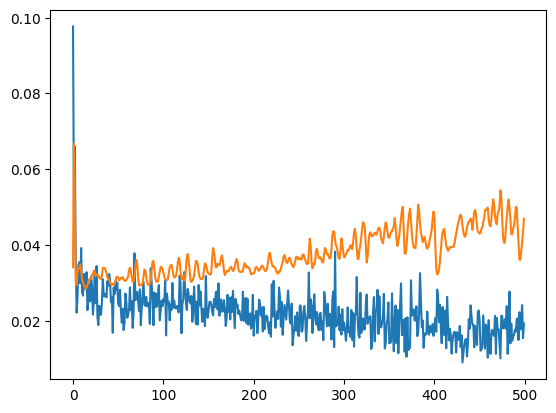

In [23]:

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])